<img src="logo.png" alt="Vegeta" width="240">

# Svarog-combining — the 1 kW and 2 kW devices from 1, 2, 4 or 8 fibre lasers

The industrial devices of `46_svarog` are built from *modules*: complete fibre lasers whose outputs are combined. This
notebook asks how — **incoherently** (intensities add, the étendue grows), **coherently** (fields add: on one axis through
a beam-splitter tree, a *filled* aperture; or side by side, a *tiled* aperture), **spectrally** (distinct wavelengths
overlapped by a grating: one channel's étendue, every channel's power) — with Hyperion's `combining` module
(`vegeta.hyperion.combining`, [docs/hyperion.md](../docs/hyperion.md)): the near and far fields on a grid, the power
accounting (Parseval, the losses, the coherent cross term, the beam-splitter's other port), the second-moment beam
metrics (σ, BPP, M² where it means something, brightness) against **one Gaussian of the same power**. Per topic, the
**1 kW** and the **2 kW** device one after the other on the same code (`designs/svarog_combining.py`); the drawings in
`designs/svarog_combining_drawings.py` (static: maps, surfaces, cross sections — no animation).

What this is *not*: the combining of **pump diodes** into a module stays in `svarog_industrial` (`PumpModules`, the (6+1)×1
combiner) — here the channels are the modules' **signal outputs**, the 30/250 power stage's LP₀₁ at 1070 nm; and nothing is
about a target — the far field is at the combiner's output, not on a workpiece or a guard (that is Part IV of 46).

In [1]:
DEBUG = False
from vegeta import mock
DEBUG = mock.setup(DEBUG)

In [2]:
import json, math, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, "designs")
from vegeta import hyperion as hy
from vegeta.hyperion import combining as cb
import svarog_combining as sc, svarog_combining_drawings as scd

pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 240); pd.set_option("display.float_format", lambda v: f"{v:.4g}")
DATA = Path("designs/data")
OUT = Path("output/47_svarog_combining"); OUT.mkdir(parents=True, exist_ok=True)
from vegeta import yanus
GATE = yanus.enter("47_svarog_combining", debug=DEBUG)      # needs vegeta.hyperion; takes 46's report (optional: the delivered powers); gives the record
REPORT_KEY = "46_svarog:notebooks/designs/data/reports/46_svarog.json"      # the take's key is written from the repository root
POWERS = sc.powers_from(GATE.inputs.get(REPORT_KEY))        # {"1kW": W, "2kW": W} as 46 delivered them, or nominal
DEVICES = list(POWERS)
print({k: f"{v:.0f} W" for k, v in POWERS.items()}, "| channel: w0 %.1f µm, M² %.1f, %.0f nm" % (sc.MODULE_W0 * 1e6, sc.MODULE_M2, sc.WAVELENGTH * 1e9))

{'1kW': '933 W', '2kW': '1811 W'} | channel: w0 11.8 µm, M² 1.0, 1070 nm


## Part 0 — the physics on 1 W channels

Before the kilowatts: four identical 1 W channels on the module's beam (w₀ 11.8 µm), so every number is per watt.
The layouts, then the four methods' near and far fields for N = 4, the two-beam fringes, and the far fields as surfaces.
What each method keeps: incoherent — every watt, no interference, the étendue is the union; coherent filled — every watt
*when in phase* (the rest leaves by the other port), one channel's étendue; coherent tiled — every watt, N² on axis but in a
lobe N times narrower, the side lobes carry the rest; spectral — every watt the grating passes, one channel's étendue.

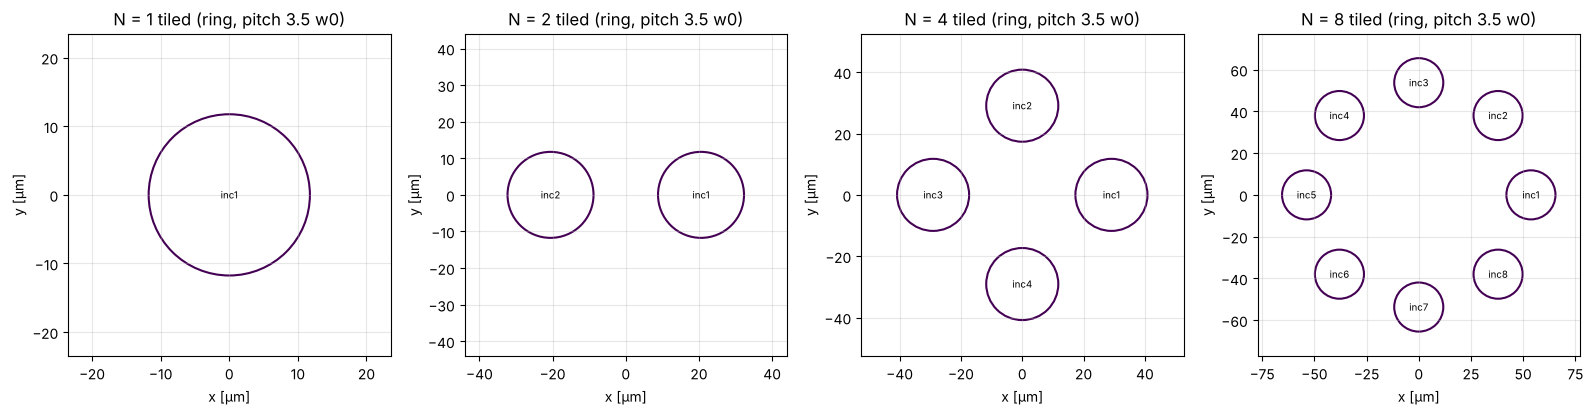

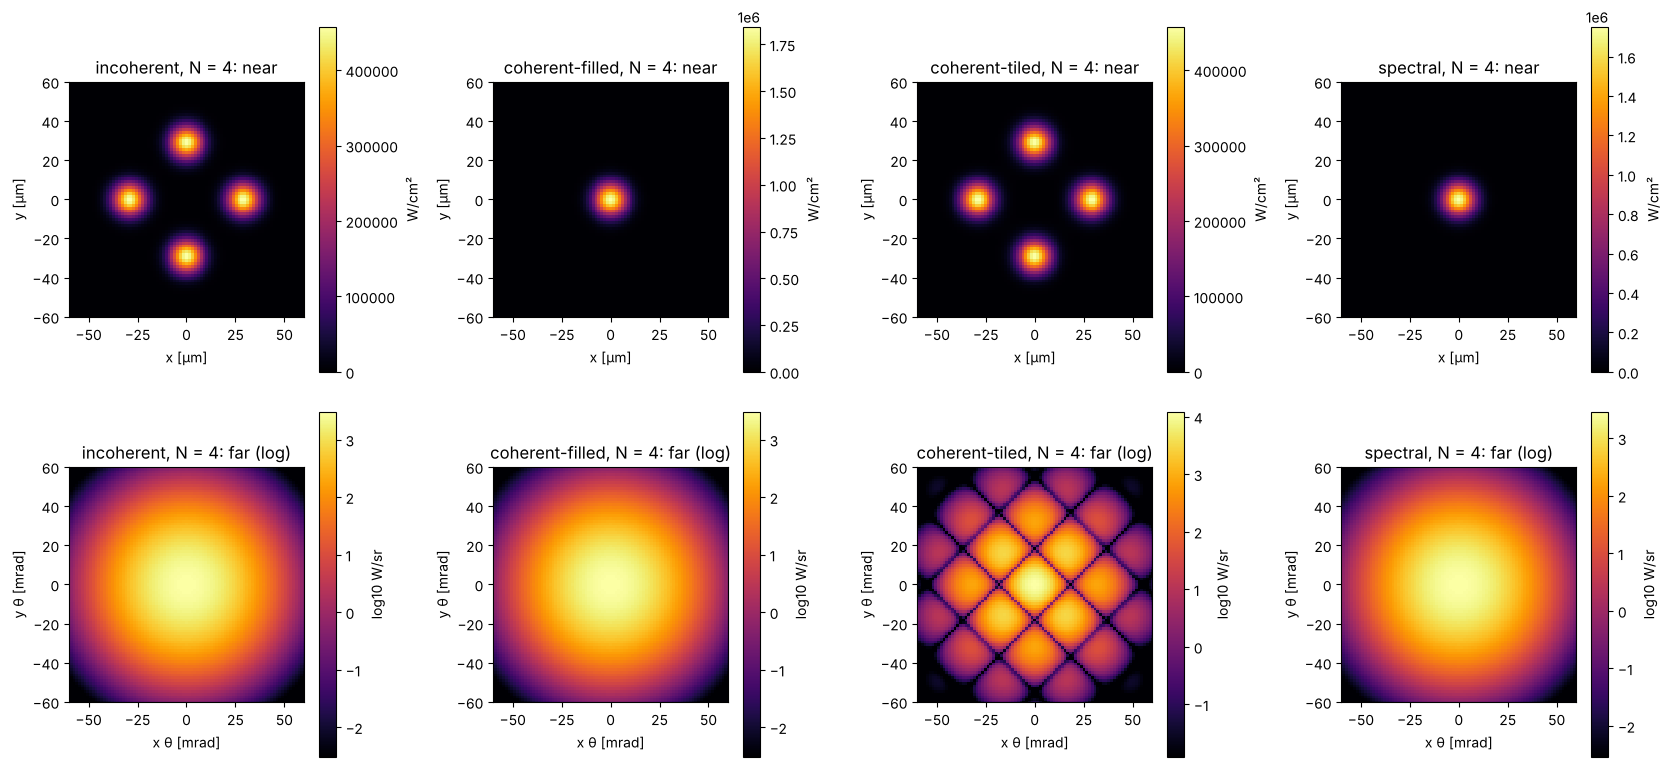

P_out [W]  efficiency  σx [µm]  σθx [mrad]  BPP [mm·mrad]    M²  brightness [W/(cm²·sr)]  on-axis [W/sr]  Parseval   overlap aperture
method          N                                                                                                                                       
one Gaussian    1          4           1    5.875       14.49        0.08515     1                3.494e+08            3031  3.12e-14         0         
incoherent      1          4           1    5.875       14.49        0.08515     1                3.494e+08            3031  3.12e-14         0         
                2          4           1    21.39       14.49         0.3099  3.64                9.598e+07            3031 1.599e-14 -1.11e-16         
                4          4           1    21.39       14.49         0.3099  3.64                2.637e+07            3031 2.265e-14         0         
                8          4           1    38.45       14.49         0.5572 6.544                8.158e+06            3031 2.176e-14  2.22e-16         
coherent-filled 1          4           1    5.875       14.49        0.08515     1                3.494e+08            3031  3.12e-14         0   filled
                2          4           1    5.875       14.49        0.08515     1                3.494e+08            3031 1.577e-14         0   filled
                4          4           1    5.875       14.49        0.08515     1                3.494e+08            3031 2.265e-14         0   filled
                8          4           1    5.875       14.49        0.08515     1                3.494e+08            3031 2.187e-14         0   filled
coherent-tiled  1          4           1    5.875       14.49        0.08515     1                3.494e+08            3031  3.12e-14         0    tiled
                2          4      0.5388    21.37        14.3         0.3055 3.587                9.739e+07            6062 1.595e-14  0.002187    tiled
                4          4      0.4147    21.37        14.3         0.3055 3.587                2.715e+07       1.212e+04 2.277e-14   0.00438    tiled
                8          4      0.2635    38.44        14.3         0.5496 6.454                8.387e+06       2.425e+04 2.189e-14  0.004375    tiled
spectral        1        3.8        0.95    5.875       14.49        0.08515     1                3.319e+08            2880 3.097e-14         0         
                2        3.8        0.95    5.875       14.49        0.08516   NaN                3.318e+08            2879 2.256e-14 2.337e-16         
                4        3.8        0.95    5.875        14.5        0.08517   NaN                3.317e+08            2879 1.695e-14         0         
                8        3.8        0.95    5.875        14.5        0.08518   NaN                3.316e+08            2879 1.017e-14 1.169e-16

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, n in zip(axes, sc.CHANNEL_COUNTS):
    scd.layout_view(sc.channel_set(n, float(n), method="incoherent"), ax=ax, title=f"N = {n} tiled (ring, pitch 3.5 w0)")
fig.tight_layout(); fig.savefig(OUT / "layouts.png", dpi=110); plt.show()
LOW = sc.study(4.0, counts=(1, 2, 4, 8), n=512, margin=30)      # 4 W shared by N channels: the normalised example, on a fine far-field grid
fig = scd.method_panel(LOW, 4, zoom_far=60, zoom_near=60); fig.savefig(OUT / "methods_n4_1W.png", dpi=110); plt.show()
display(pd.DataFrame(sc.metrics_table(LOW, 4.0)).set_index(["method", "N"]))

Reading the table: the **Parseval** column is the numerical check (far-field power = near-field power, 1e-15); **overlap**
is the physical cross term of tiled channels whose Gaussians touch (0.4 % at a 3.5 w₀ pitch) — zero for incoherent sums and
for the filled aperture, whose output power *is* the near field's (the beam splitter's other port takes the rest when the
phases are off). The coherent filled rows equal the one-Gaussian row: that is the combining that keeps the brightness.

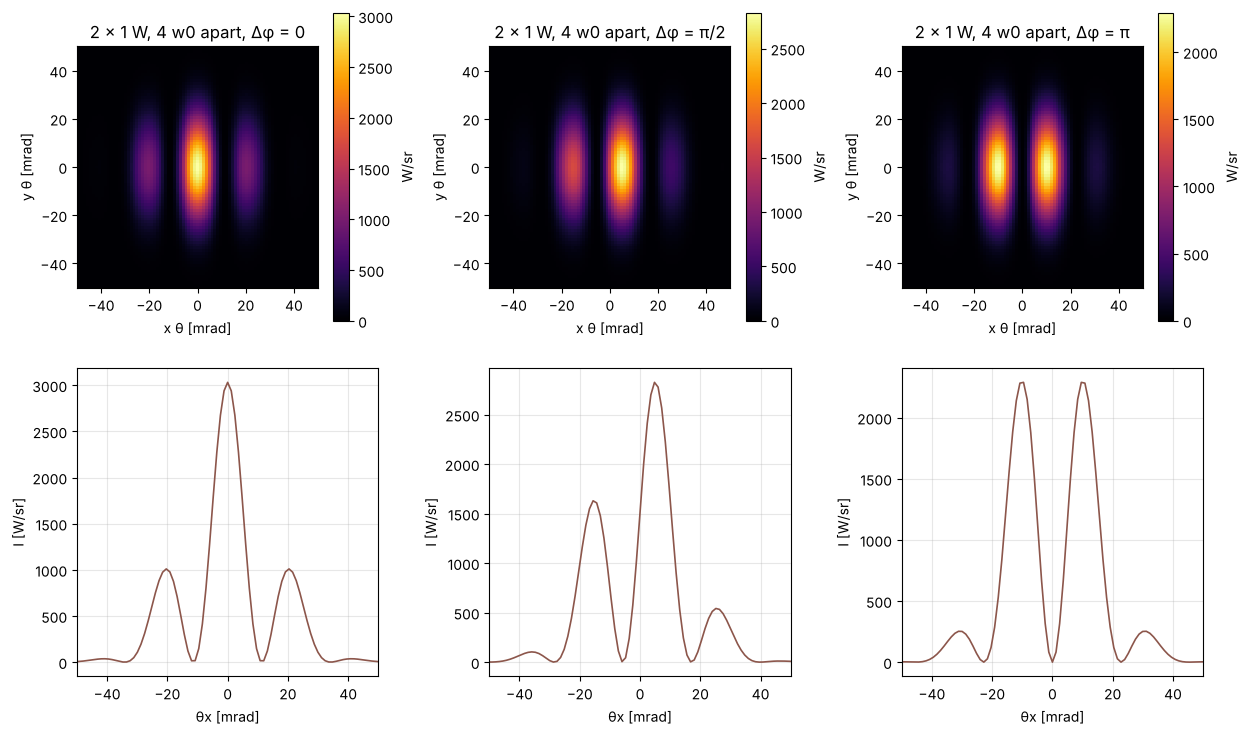

fringe period λ/d = 22.8 mrad; the π case has 1.1e-29 W/sr on axis against 3.03e+03 in phase — the power is all in the side lobes (P_out 2.000 W)


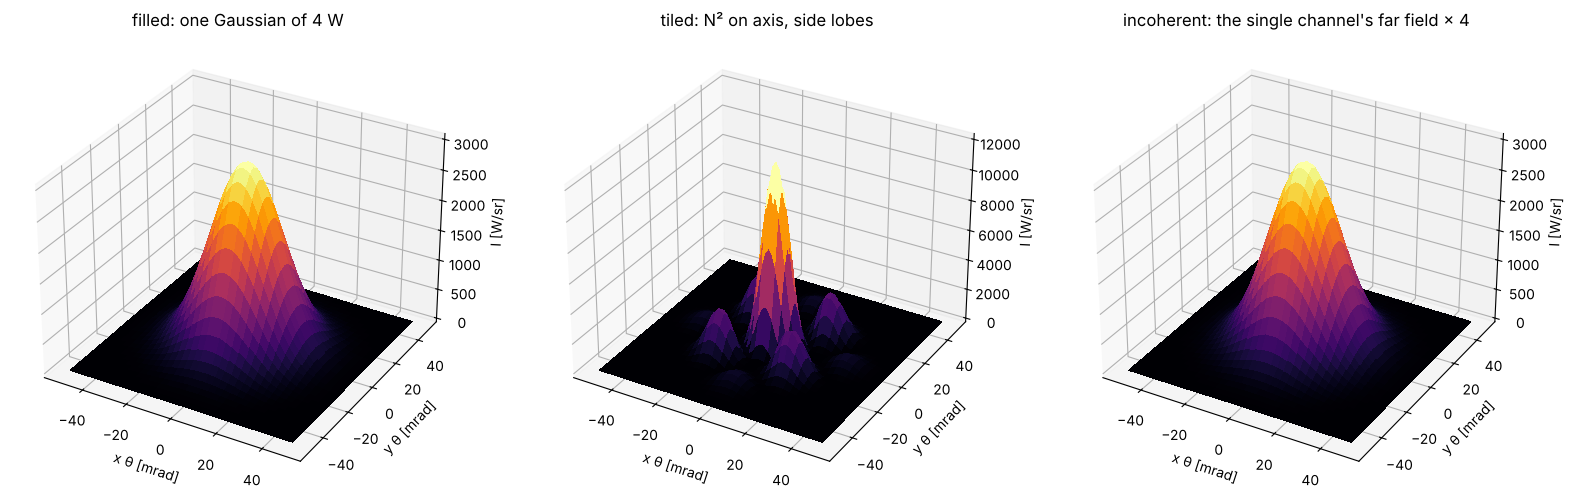

In [4]:
pairs = {f"2 × 1 W, 4 w0 apart, Δφ = {lab}": sc.interference_pair(2.0, phase=ph) for lab, ph in (("0", 0.0), ("π/2", math.pi / 2), ("π", math.pi))}
fig = scd.interference_view(pairs, zoom=50); fig.savefig(OUT / "fringes.png", dpi=110); plt.show()
print("fringe period λ/d = %.1f mrad; the π case has %.1e W/sr on axis against %.3g in phase — the power is all in the side lobes (P_out %.3f W)" % (
    sc.WAVELENGTH / (4 * sc.MODULE_W0) * 1e3, pairs[list(pairs)[2]].I_far_axis, pairs[list(pairs)[0]].I_far_axis, pairs[list(pairs)[2]].power_out))
fig = plt.figure(figsize=(16, 5))
for j, (m, lab) in enumerate((("coherent-filled", "filled: one Gaussian of 4 W"), ("coherent-tiled", "tiled: N² on axis, side lobes"), ("incoherent", "incoherent: the single channel's far field × 4"))):
    scd.surface_view(LOW[m][4], far=True, ax=fig.add_subplot(1, 3, j + 1, projection="3d"), title=lab, zoom=50, stride=1)
fig.tight_layout(); fig.savefig(OUT / "surfaces_n4_1W.png", dpi=110); plt.show()

## Part I — the devices: 1 kW, then 2 kW, from N channels

Each device's delivered power (from 46's report) is shared by N = 1, 2, 4, 8 channels and combined every way; the
reference is one Gaussian of that power on the module's beam. N = 1 is the single stage as 46 built it (the 1 kW) or a
hypothetical single 2 kW stage; N = 2 is the 2 kW as 46's route A builds it. The 2 kW is analysed on the same code right
after the 1 kW. `topic_device` is the code every device runs.

— 1kW: 933 W delivered, 16 combinations on a 512² grid in 2.9 s


P_out [W]  efficiency  σx [µm]  σθx [mrad]  BPP [mm·mrad]    M²  brightness [W/(cm²·sr)]  on-axis [W/sr]    overlap aperture
method          N                                                                                                                              
one Gaussian    1      933.3           1    5.875       14.49        0.08515     1                8.151e+10       7.072e+05          0         
incoherent      1      933.3           1    5.875       14.49        0.08515     1                8.151e+10       7.072e+05          0         
                2      933.3           1    21.39       14.49         0.3099  3.64                2.239e+10       7.072e+05 -3.655e-16         
                4      933.3           1    21.39       14.49         0.3099  3.64                6.152e+09       7.072e+05          0         
                8      933.3           1    38.45       14.49         0.5572 6.544                1.903e+09       7.072e+05  1.218e-16         
coherent-filled 1      933.3           1    5.875       14.49        0.08515     1                8.151e+10       7.072e+05          0   filled
                2      933.3           1    5.875       14.49        0.08515     1                8.151e+10       7.072e+05          0   filled
                4      933.3           1    5.875       14.49        0.08515     1                8.151e+10       7.072e+05          0   filled
                8      933.3           1    5.875       14.49        0.08515     1                8.151e+10       7.072e+05          0   filled
coherent-tiled  1      933.3           1    5.875       14.49        0.08515     1                8.151e+10       7.072e+05          0    tiled
                2      933.3      0.5388    21.37        14.3         0.3055 3.587                2.272e+10       1.414e+06   0.002187    tiled
                4      933.3      0.4147    21.37        14.3         0.3055 3.587                6.334e+09       2.829e+06    0.00438    tiled
                8      933.3      0.2635    38.44        14.3         0.5496 6.454                1.957e+09       5.658e+06   0.004375    tiled
spectral        1      886.6        0.95    5.875       14.49        0.08515     1                7.744e+10       6.719e+05 -1.282e-16         
                2      886.6        0.95    5.875       14.49        0.08516   NaN                7.742e+10       6.718e+05 -1.282e-16         
                4      886.6        0.95    5.875        14.5        0.08517   NaN                 7.74e+10       6.717e+05          0         
                8      886.6        0.95    5.875        14.5        0.08518   NaN                7.737e+10       6.717e+05 -2.565e-16

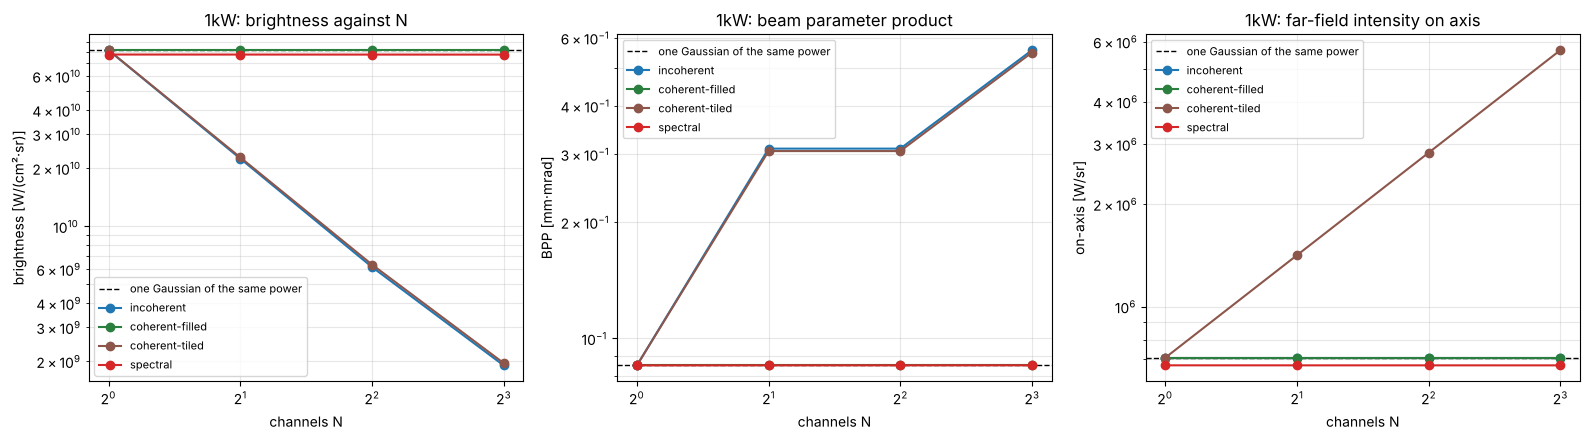

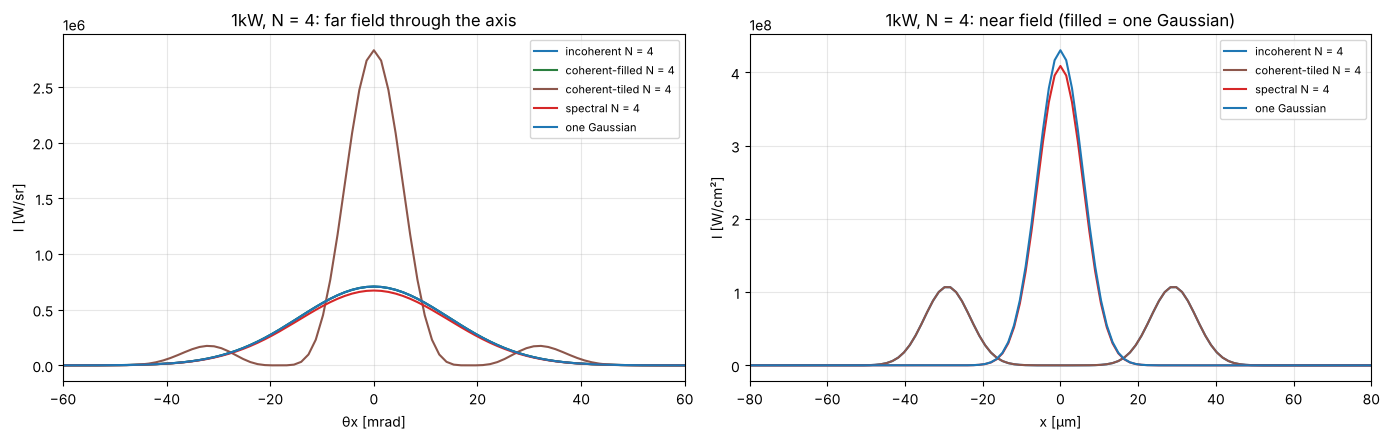

In [5]:
ST, TAB = {}, {}

def topic_device(k: str):
    t0 = time.time()
    ST[k] = sc.study(POWERS[k], n=512, margin=30)                  # a 1.3 mm window: the far-field pixel is 0.8 mrad
    TAB[k] = pd.DataFrame(sc.metrics_table(ST[k], POWERS[k]))
    print(f"— {k}: {POWERS[k]:.0f} W delivered, {len(TAB[k]) - 1} combinations on a {ST[k]['incoherent'][8].grid.n}² grid in {time.time() - t0:.1f} s")
    display(TAB[k].set_index(["method", "N"]).drop(columns=["Parseval"]))
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    rows = TAB[k].to_dict("records")
    scd.metrics_view(rows, "brightness [W/(cm²·sr)]", ax=axes[0], title=f"{k}: brightness against N")
    scd.metrics_view(rows, "BPP [mm·mrad]", ax=axes[1], title=f"{k}: beam parameter product")
    scd.metrics_view(rows, "on-axis [W/sr]", ax=axes[2], title=f"{k}: far-field intensity on axis")
    fig.tight_layout(); fig.savefig(OUT / f"metrics_{k}.png", dpi=110); plt.show()
    far = {f"{m} N = 4": ST[k][m][4] for m in ST[k]} | {"one Gaussian": sc.equivalent(POWERS[k], ST[k]["incoherent"][4].grid)}
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    scd.cross_sections(far, far=True, ax=axes[0], title=f"{k}, N = 4: far field through the axis", zoom=60)
    scd.cross_sections({kk: v for kk, v in far.items() if "filled" not in kk}, far=False, ax=axes[1], title=f"{k}, N = 4: near field (filled = one Gaussian)", zoom=80)
    fig.tight_layout(); fig.savefig(OUT / f"sections_{k}.png", dpi=110); plt.show()

topic_device("1kW")

— 2kW: 1811 W delivered, 16 combinations on a 512² grid in 3.0 s


P_out [W]  efficiency  σx [µm]  σθx [mrad]  BPP [mm·mrad]    M²  brightness [W/(cm²·sr)]  on-axis [W/sr]    overlap aperture
method          N                                                                                                                              
one Gaussian    1       1811           1    5.875       14.49        0.08515     1                1.581e+11       1.372e+06 -1.256e-16         
incoherent      1       1811           1    5.875       14.49        0.08515     1                1.581e+11       1.372e+06 -1.256e-16         
                2       1811           1    21.39       14.49         0.3099  3.64                4.344e+10       1.372e+06 -2.512e-16         
                4       1811           1    21.39       14.49         0.3099  3.64                1.193e+10       1.372e+06          0         
                8       1811           1    38.45       14.49         0.5572 6.544                3.693e+09       1.372e+06          0         
coherent-filled 1       1811           1    5.875       14.49        0.08515     1                1.581e+11       1.372e+06          0   filled
                2       1811           1    5.875       14.49        0.08515     1                1.581e+11       1.372e+06          0   filled
                4       1811           1    5.875       14.49        0.08515     1                1.581e+11       1.372e+06          0   filled
                8       1811           1    5.875       14.49        0.08515     1                1.581e+11       1.372e+06          0   filled
coherent-tiled  1       1811           1    5.875       14.49        0.08515     1                1.581e+11       1.372e+06 -1.256e-16    tiled
                2       1811      0.5388    21.37        14.3         0.3055 3.587                4.408e+10       2.744e+06   0.002187    tiled
                4       1811      0.4147    21.37        14.3         0.3055 3.587                1.229e+10       5.488e+06    0.00438    tiled
                8       1811      0.2635    38.44        14.3         0.5496 6.454                3.796e+09       1.098e+07   0.004375    tiled
spectral        1       1720        0.95    5.875       14.49        0.08515     1                1.502e+11       1.303e+06          0         
                2       1720        0.95    5.875       14.49        0.08516   NaN                1.502e+11       1.303e+06  1.322e-16         
                4       1720        0.95    5.875        14.5        0.08517   NaN                1.502e+11       1.303e+06  1.322e-16         
                8       1720        0.95    5.875        14.5        0.08518   NaN                1.501e+11       1.303e+06          0

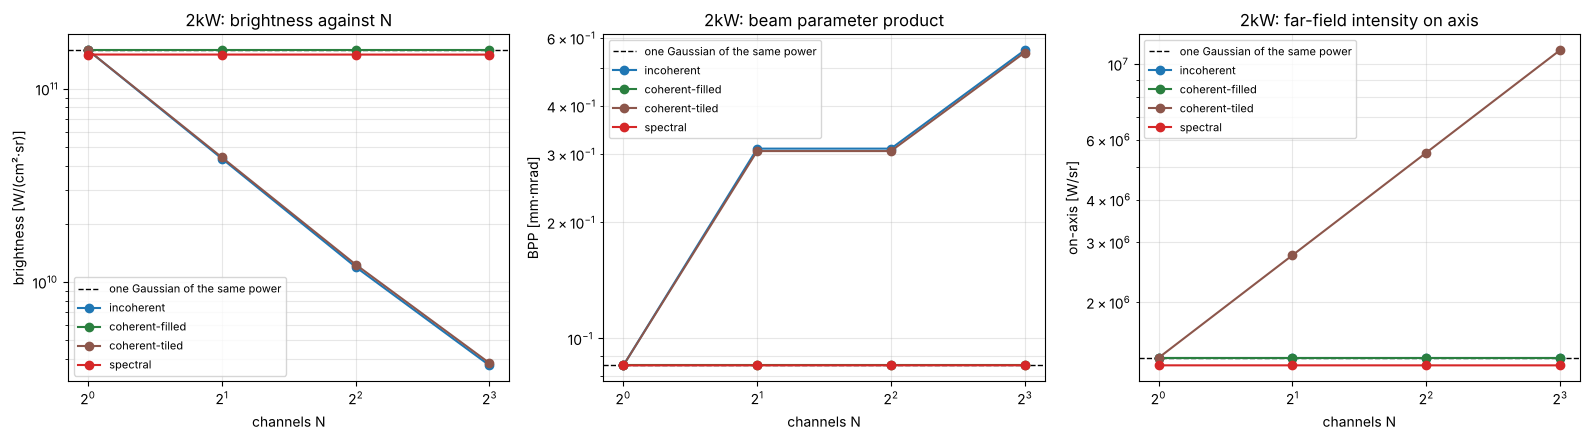

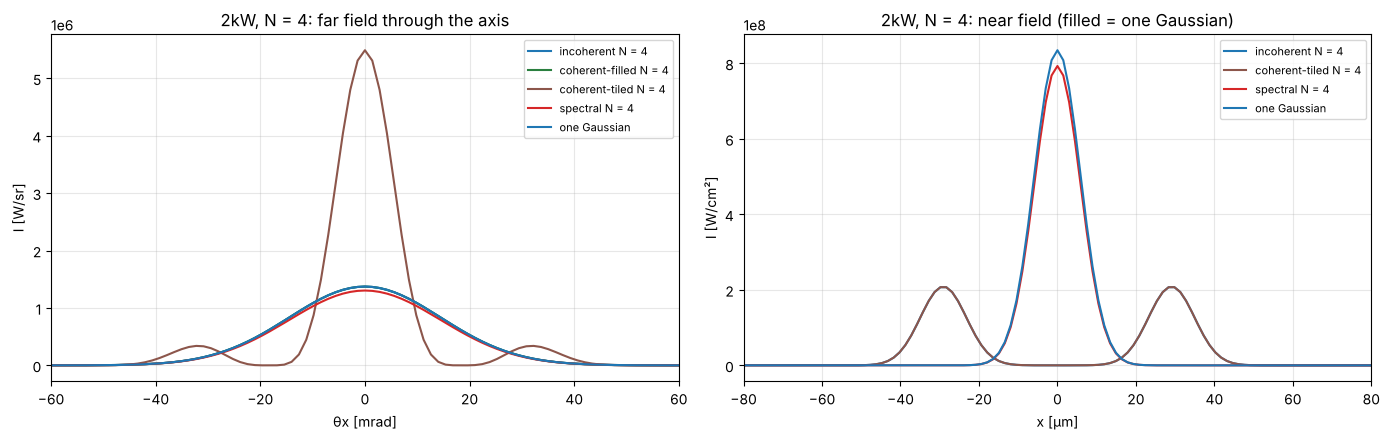

In [6]:
topic_device("2kW")

Across both devices the ranking does not depend on the power: **brightness** is one Gaussian's for coherent-filled and
(× 0.95, the grating) for spectral, whatever N; it falls with N for incoherent and tiled combining because the étendue is
the array's — the tiled array's N² on-axis peak sits in a lobe N times narrower, so the *brightness* (power per étendue)
is the incoherent sum's. The step from 1 kW to 2 kW doubles every power and brightness and changes no shape: the
combiner's choice is made on the étendue the process fibre can carry (46 Part III: 50 µm, NA 0.12 → a BPP of 3 mm·mrad).

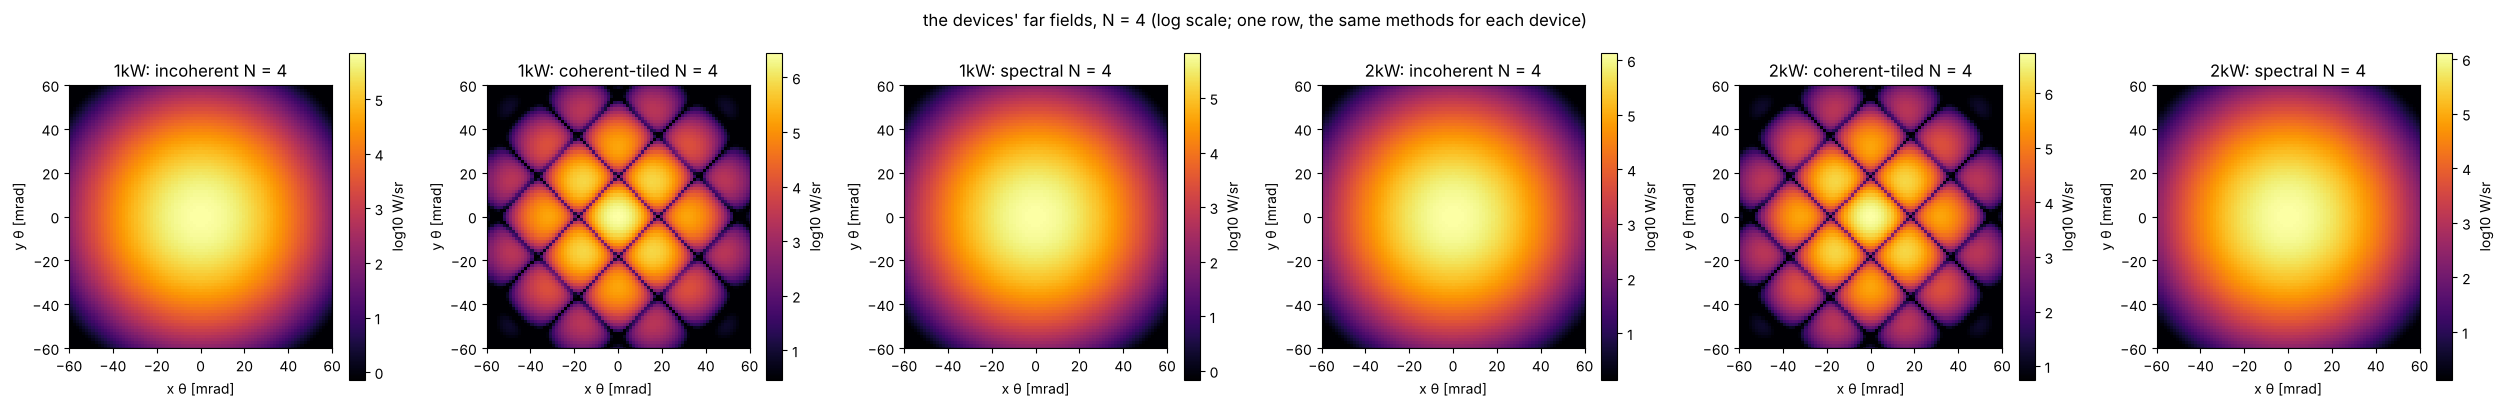

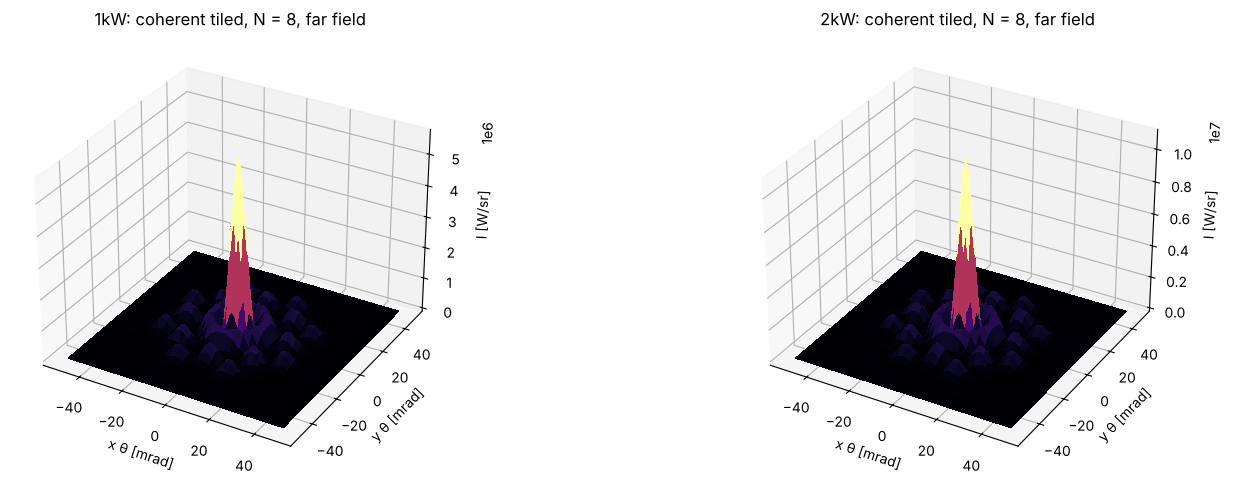

In [7]:
fig = scd.side_by_side({f"{k}: {m} N = 4": ST[k][m][4] for k in DEVICES for m in ("incoherent", "coherent-tiled", "spectral")}, far=True, zoom=60, log=True,
                       title="the devices' far fields, N = 4 (log scale; one row, the same methods for each device)")
fig.savefig(OUT / "far_fields_devices.png", dpi=110); plt.show()
fig = plt.figure(figsize=(16, 5))
for j, k in enumerate(DEVICES):
    scd.surface_view(ST[k]["coherent-tiled"][8], far=True, ax=fig.add_subplot(1, 2, j + 1, projection="3d"), title=f"{k}: coherent tiled, N = 8, far field", zoom=50, stride=1)
fig.tight_layout(); fig.savefig(OUT / "surfaces_tiled_n8.png", dpi=110); plt.show()

## Part II — the coherent combiner's phase sensitivity

Coherent combining lives on the phases: Gaussian random phase errors of rms σ on every channel, 30 draws per σ — the mean
on-axis gain against the in-phase case and the closed form 1/N + (1 − 1/N) e^(−σ²) (the power that stays in the coherent
sum), the band the central-lobe efficiency's spread. The same for both devices: the phase sensitivity does not know the
power (and the plot shows it).

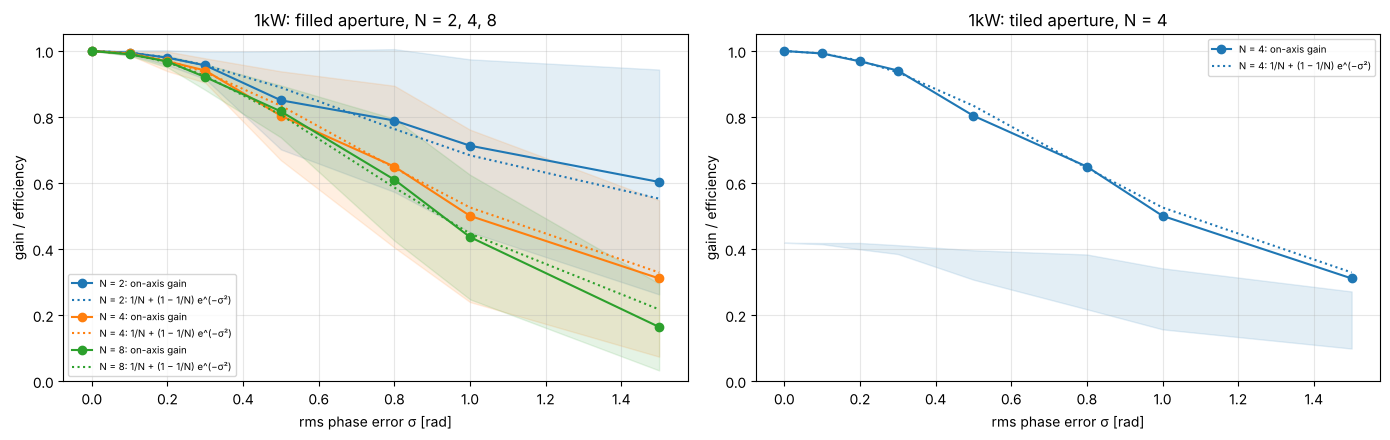

on-axis gain  closed form  central-lobe efficiency
aperture N σ [rad]                                                    
filled   2 0                   1            1                        1
           0.3            0.9564        0.957                   0.9564
           0.5            0.8506       0.8894                   0.8506
           1              0.7131       0.6839                   0.7131
         4 0                   1            1                        1
           0.3            0.9409       0.9354                   0.9409
           0.5            0.8037       0.8341                   0.8037
           1              0.5005       0.5259                   0.5005
         8 0                   1            1                        1
           0.3            0.9209       0.9247                   0.9209
           0.5            0.8169       0.8065                   0.8169
           1              0.4363       0.4469                   0.4363
tiled    4 0                   1            1                   0.4191
           0.3            0.9409       0.9354                   0.3984
           0.5            0.8037       0.8341                   0.3518
           1              0.5005       0.5259                   0.2493

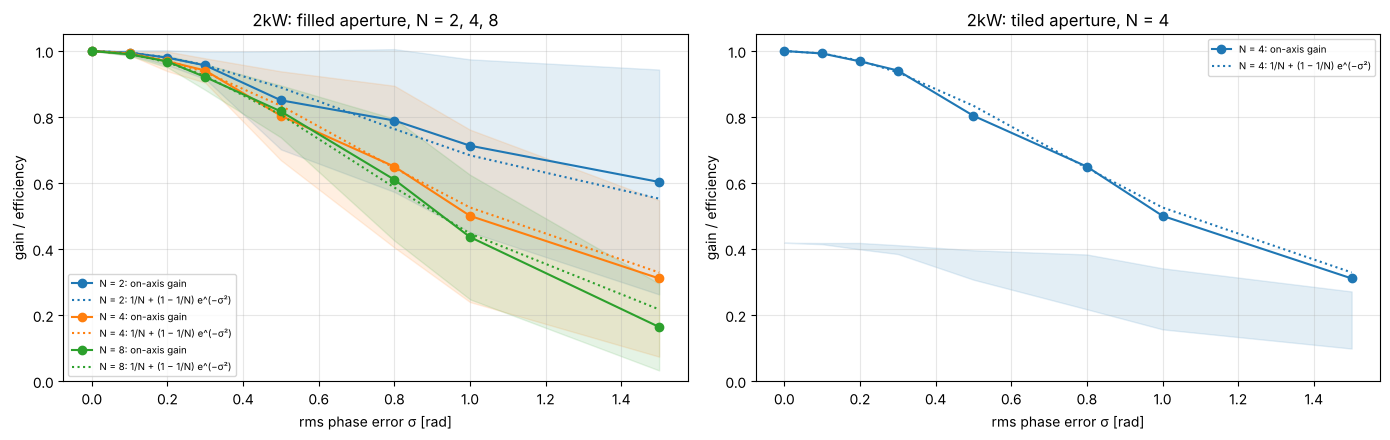

on-axis gain  closed form  central-lobe efficiency
aperture N σ [rad]                                                    
filled   2 0                   1            1                        1
           0.3            0.9564        0.957                   0.9564
           0.5            0.8506       0.8894                   0.8506
           1              0.7131       0.6839                   0.7131
         4 0                   1            1                        1
           0.3            0.9409       0.9354                   0.9409
           0.5            0.8037       0.8341                   0.8037
           1              0.5005       0.5259                   0.5005
         8 0                   1            1                        1
           0.3            0.9209       0.9247                   0.9209
           0.5            0.8169       0.8065                   0.8169
           1              0.4363       0.4469                   0.4363
tiled    4 0                   1            1                   0.4191
           0.3            0.9409       0.9354                   0.3984
           0.5            0.8037       0.8341                   0.3518
           1              0.5005       0.5259                   0.2493

In [8]:
PH = {}

def topic_phase(k: str):
    PH[k] = {"filled": sc.phase_study(POWERS[k], counts=(2, 4, 8), aperture="filled"), "tiled": sc.phase_study(POWERS[k], counts=(4,), aperture="tiled")}
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    scd.phase_view(PH[k]["filled"], ax=axes[0], title=f"{k}: filled aperture, N = 2, 4, 8")
    scd.phase_view(PH[k]["tiled"], ax=axes[1], title=f"{k}: tiled aperture, N = 4")
    fig.tight_layout(); fig.savefig(OUT / f"phase_{k}.png", dpi=110); plt.show()
    rows = [{"aperture": ap, "N": n, "σ [rad]": s, "on-axis gain": g, "closed form": c, "central-lobe efficiency": e}
            for ap, d in PH[k].items() for n, ps in d.items() for s, g, c, e in zip(ps["sigma_phase"], ps["axis_gain"], ps["closed_form"], ps["efficiency"])]
    display(pd.DataFrame(rows).query("`σ [rad]` in (0.0, 0.3, 0.5, 1.0)").set_index(["aperture", "N", "σ [rad]"]))

for k in DEVICES:
    topic_phase(k)

A σ of 0.3 rad (λ/20) costs ~8 % on axis, 0.5 rad ~20 %, 1 rad half: the phase lock has to hold the channels to a
twentieth of a wave for the combined beam to be worth its complexity — the known requirement of coherent combining
(Fan 2005, Augst et al. 2007). The tiled aperture pays the same on axis and loses its central lobe faster.

## Part III — losses, the grating's residual, the multimode check

Every channel losing the same fraction (a splice, a coating), then one channel alone losing it (a bad splice among clean
ones: the coherent filled sum then also pays an imbalance penalty, 1 − (Σ√Pᵢ)²/(N ΣPᵢ) — second order, 0.05 % for one
channel at −10 %: a bad splice costs its power, not the coherence); the spectral combiner
against the share of the grating's angular dispersion left uncorrected; and the incoherent and spectral rows again with the
LMA stage's measured M² of 1.3 (the far field widens by M², the brightness falls by M⁴, nothing else moves).

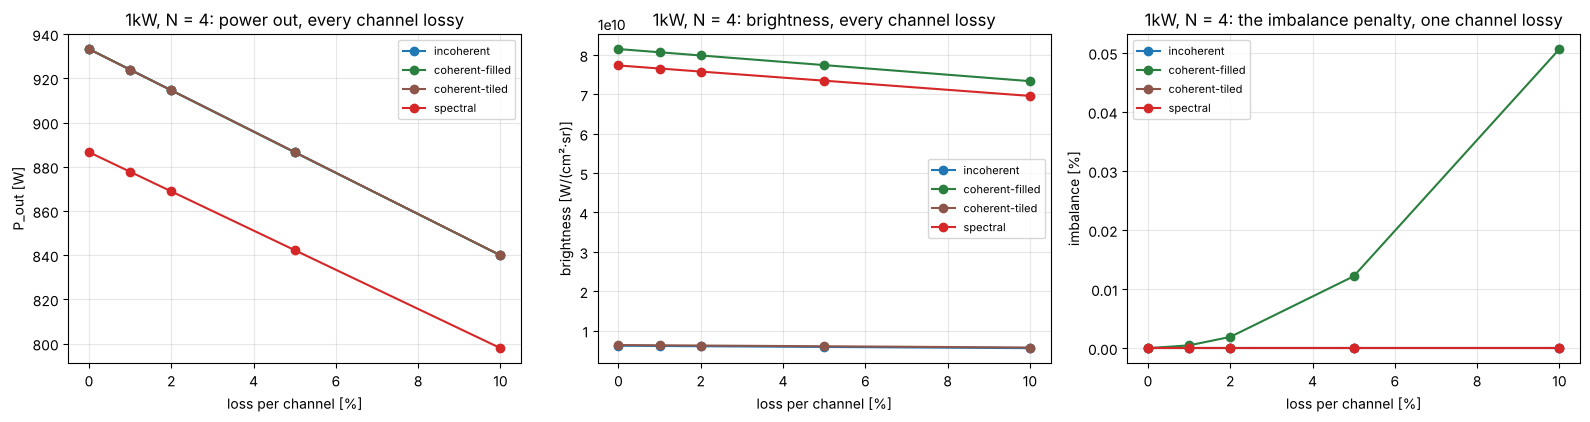

,residual [mrad/nm],pointing max [mrad],σθx [mrad],σθy [mrad],BPP x [mm·mrad],brightness [W/(cm²·sr)]
residual share,,,,,,
0.000000,0.000000,0.000000,14.502613,14.502613,0.085209,77327526735.078903
0.050000,0.100000,0.450000,14.506495,14.502613,0.085232,77306835004.431000
0.100000,0.200000,0.900000,14.518134,14.502613,0.085300,77244859320.814041
0.250000,0.500000,2.250000,14.599347,14.502613,0.085777,76815162825.759613
0.500000,1.000000,4.500000,14.885778,14.502613,0.087460,75337090222.739975


,,M² channel,P_out [W],efficiency,σx [µm],σθx [mrad],BPP [mm·mrad],M²,brightness [W/(cm²·sr)],on-axis [W/sr]
method,N,,,,,,,,,
incoherent,1,1.300000,933.254301,1.000000,5.875416,18.944611,0.111307,1.307225,47701458174.279480,418387.424635
spectral,1,1.300000,886.591586,0.950000,5.875416,18.944611,0.111307,1.307225,45316385265.565521,397468.053403
incoherent,4,1.300000,933.254301,1.000000,21.386837,18.912132,0.404471,4.750214,3612486006.803112,418446.691440
spectral,4,1.300000,886.591586,0.950000,5.875416,18.945859,0.111315,nan,45310414830.963974,397464.260623


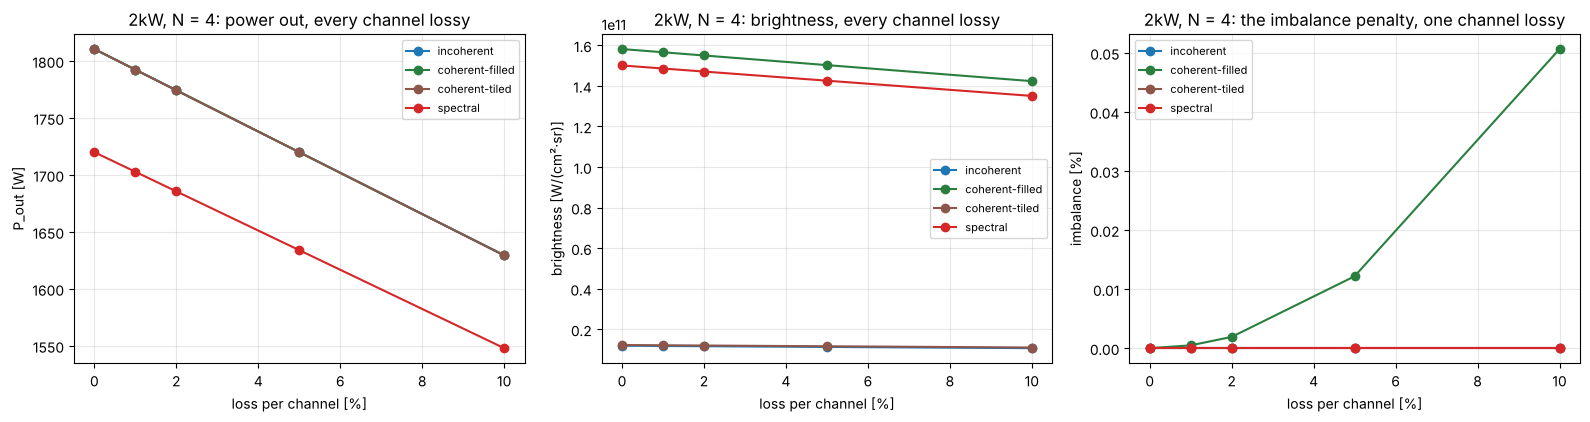

,residual [mrad/nm],pointing max [mrad],σθx [mrad],σθy [mrad],BPP x [mm·mrad],brightness [W/(cm²·sr)]
residual share,,,,,,
0.000000,0.000000,0.000000,14.502613,14.502613,0.085209,150015401866.053040
0.050000,0.100000,0.450000,14.506495,14.502613,0.085232,149975259908.596069
0.100000,0.200000,0.900000,14.518134,14.502613,0.085300,149855027082.379089
0.250000,0.500000,2.250000,14.599347,14.502613,0.085777,149021415881.973602
0.500000,1.000000,4.500000,14.885778,14.502613,0.087460,146153955032.115479


,,M² channel,P_out [W],efficiency,σx [µm],σθx [mrad],BPP [mm·mrad],M²,brightness [W/(cm²·sr)],on-axis [W/sr]
method,N,,,,,,,,,
incoherent,1,1.300000,1810.513344,1.000000,5.875416,18.944611,0.111307,1.307225,92540828858.102188,811671.603792
spectral,1,1.300000,1719.987677,0.950000,5.875416,18.944611,0.111307,1.307225,87913787415.197052,771088.023602
incoherent,4,1.300000,1810.513344,1.000000,21.386837,18.912132,0.404471,4.750214,7008222853.198038,811786.581393
spectral,4,1.300000,1719.987677,0.950000,5.875416,18.945859,0.111315,nan,87902204772.070068,771080.665609


In [9]:
LS, SP, MM = {}, {}, {}

def topic_losses(k: str):
    LS[k] = {"all channels": sc.loss_study(POWERS[k]), "one channel": sc.loss_study(POWERS[k], one_channel=True)}
    SP[k] = sc.spectral_residual(POWERS[k])
    MM[k] = sc.multimode_check(POWERS[k], counts=(1, 4))
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    scd.loss_view(LS[k]["all channels"], "P_out [W]", ax=axes[0], title=f"{k}, N = 4: power out, every channel lossy")
    scd.loss_view(LS[k]["all channels"], ax=axes[1], title=f"{k}, N = 4: brightness, every channel lossy")
    scd.loss_view(LS[k]["one channel"], "imbalance [%]", ax=axes[2], title=f"{k}, N = 4: the imbalance penalty, one channel lossy")
    fig.tight_layout(); fig.savefig(OUT / f"losses_{k}.png", dpi=110); plt.show()
    display(pd.DataFrame(SP[k]).set_index("residual share").style.set_caption(f"{k}: spectral combining, N = 4, against the residual dispersion"))
    display(pd.DataFrame(MM[k]).set_index(["method", "N"]).drop(columns=["Parseval", "overlap", "aperture"]).style.set_caption(f"{k}: the channels at M² {sc.MODULE_M2_MEASURED}"))

for k in DEVICES:
    topic_losses(k)

### Reading it

- **Power and brightness are different questions.** Every method delivers the channels' power (minus its own loss: the
  grating's 5 %, the beam splitter's other port when the phases are off); only coherent-filled and spectral combining keep
  one channel's **étendue**, so only they keep the brightness. Incoherent and tiled combining deliver the power into an
  étendue N times larger — the tiled array's N² on-axis peak is not brightness, it is a narrower lobe with side lobes.
- **For the welding devices the étendue is set by the process fibre**, not by the combiner: a 50 µm NA 0.12 fibre carries
  a BPP of 3 mm·mrad, forty times the single channel's. Incoherent combining of 2 (route A of the 2 kW) or even 8 modules
  fits in it with room to spare — the cheap, robust choice; coherent or spectral combining buys brightness the head cannot
  use. They matter where the beam must stay near-diffraction-limited (remote welding over metres, a long focal length).
- **Coherent combining asks for λ/20 phase control** and balanced channels; **spectral combining asks for the Yb band** (eight
  channels at 3 nm fit) and a grating whose residual dispersion stays under a few percent.
- **What is not modelled**: a multimode channel's coherent combining (refused: its modes do not add as one field), the
  grating's own thermal lens, polarisation, the combiner's hardware — the next line of `svarog_todo.md`.

In [10]:
def _j(o):
    if hasattr(o, "tolist"):
        return o.tolist()
    if hasattr(o, "to_dict"):
        return o.to_dict()
    if isinstance(o, float) and not math.isfinite(o):
        return None
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return str(o)

REC = sc.record(POWERS, ST, PH, LS, {k: {"residual": SP[k], "multimode": MM[k]} for k in DEVICES},
                note="channels = the modules' signal outputs; pump combining stays in svarog_industrial; nothing here is a target")
REC["meta"]["notebook"] = "47_svarog_combining"; REC["meta"]["debug"] = DEBUG; REC["meta"]["powers_from"] = str(GATE.inputs.get(REPORT_KEY) or "nominal")
(DATA / "reports").mkdir(parents=True, exist_ok=True)
(DATA / "reports" / "47_svarog_combining.json").write_text(json.dumps(REC, indent=1, default=_j))
print("report:", DATA / "reports" / "47_svarog_combining.json", f"{(DATA / 'reports' / '47_svarog_combining.json').stat().st_size / 1024:.0f} kB")

report: designs/data/reports/47_svarog_combining.json 83 kB


In [11]:
STAMPS = GATE.leave()          # the record, written by this run and stamped